# Notebook 03 — Segmentation & Tenure

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business questions answered:**
- **Q3:** Which customer segments churn the most?
- **Q7:** Which acquisition channels produce higher-churn customers?

**Evidence source:** `sql/05_segmentation.sql` and `sql/06_channel_and_tenure.sql`

**Confounding note:** App Store channel is confounded with Starter plan (by generator design).
All cross-tab analyses are shown explicitly.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. Churn by Plan (Q3)

In [2]:
df_plan = pd.read_sql('SELECT * FROM churn_by_plan', conn)
print(df_plan.to_string(index=False))

   plan  total_customers  voluntary_churns  involuntary_churns  total_churns  voluntary_churn_pct  involuntary_churn_pct  total_churn_pct  total_churn_pct_wilson_lower  total_churn_pct_wilson_upper
  Scale             4008              1929                 344          2273                48.13                   8.58            56.71                         55.18                         58.25
Starter            16273              7716                1511          9227                47.42                   9.29            56.70                         55.94                         57.46
 Growth             9719              4590                 890          5480                47.23                   9.16            56.38                         55.40                         57.37


<cell>:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


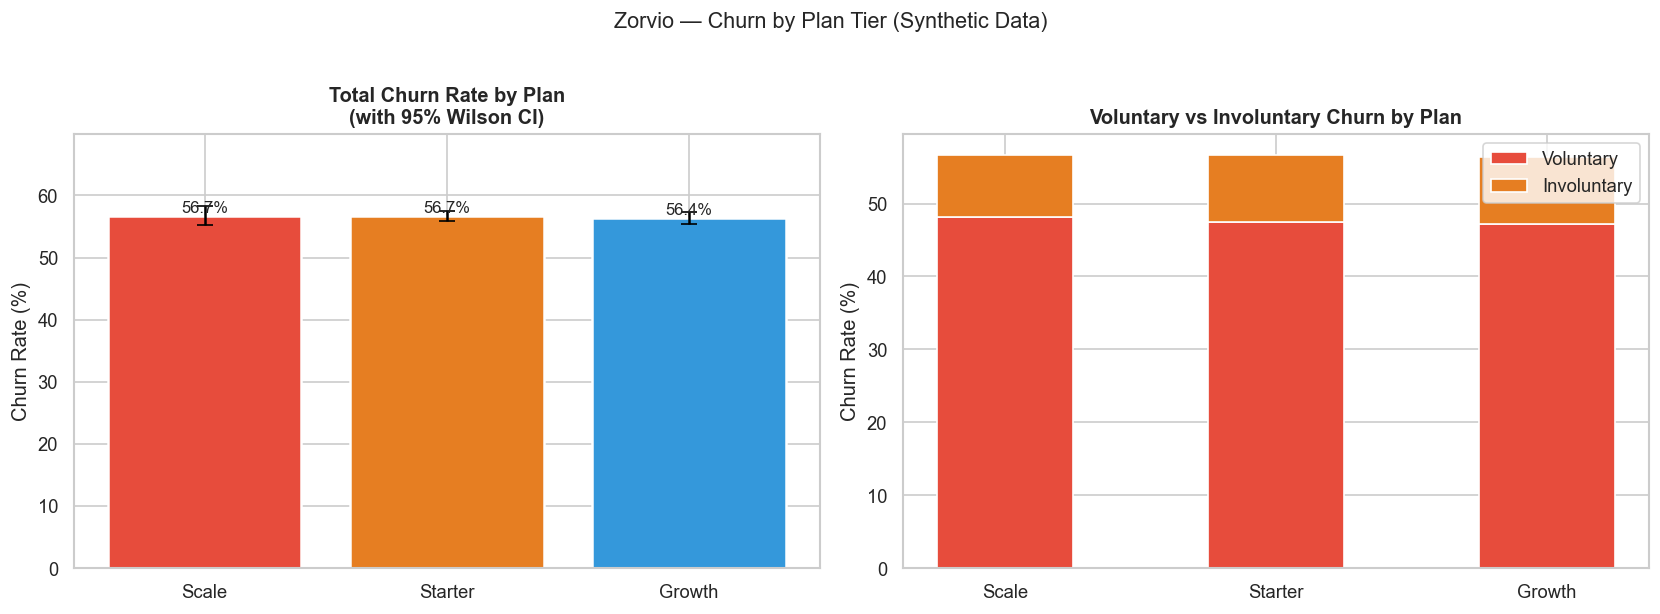

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: total churn % with Wilson CI error bars
ax = axes[0]
plans = df_plan['plan']
mid = df_plan['total_churn_pct']
lo  = df_plan['total_churn_pct_wilson_lower']
hi  = df_plan['total_churn_pct_wilson_upper']
colors = ['#e74c3c', '#e67e22', '#3498db']
bars = ax.bar(plans, mid, color=colors[:len(plans)], edgecolor='white', linewidth=1.5)
ax.errorbar(plans, mid, yerr=[mid - lo, hi - mid], fmt='none', color='black', capsize=5, linewidth=1.5)
ax.set_title('Total Churn Rate by Plan\n(with 95% Wilson CI)', fontsize=12, fontweight='bold')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, max(hi) * 1.2)
for bar, val in zip(bars, mid):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.1f}%', ha='center', fontsize=10)

# Right: voluntary vs involuntary stacked
ax2 = axes[1]
x = np.arange(len(plans))
width = 0.5
p1 = ax2.bar(x, df_plan['voluntary_churn_pct'], width, label='Voluntary', color='#e74c3c')
p2 = ax2.bar(x, df_plan['involuntary_churn_pct'], width, bottom=df_plan['voluntary_churn_pct'], label='Involuntary', color='#e67e22')
ax2.set_xticks(x)
ax2.set_xticklabels(plans)
ax2.set_title('Voluntary vs Involuntary Churn by Plan', fontsize=12, fontweight='bold')
ax2.set_ylabel('Churn Rate (%)')
ax2.legend()

plt.suptitle('Zorvio — Churn by Plan Tier (Synthetic Data)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_churn_by_plan.png', bbox_inches='tight')
plt.show()

## 2. Churn by Billing Cycle and City Tier

<cell>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


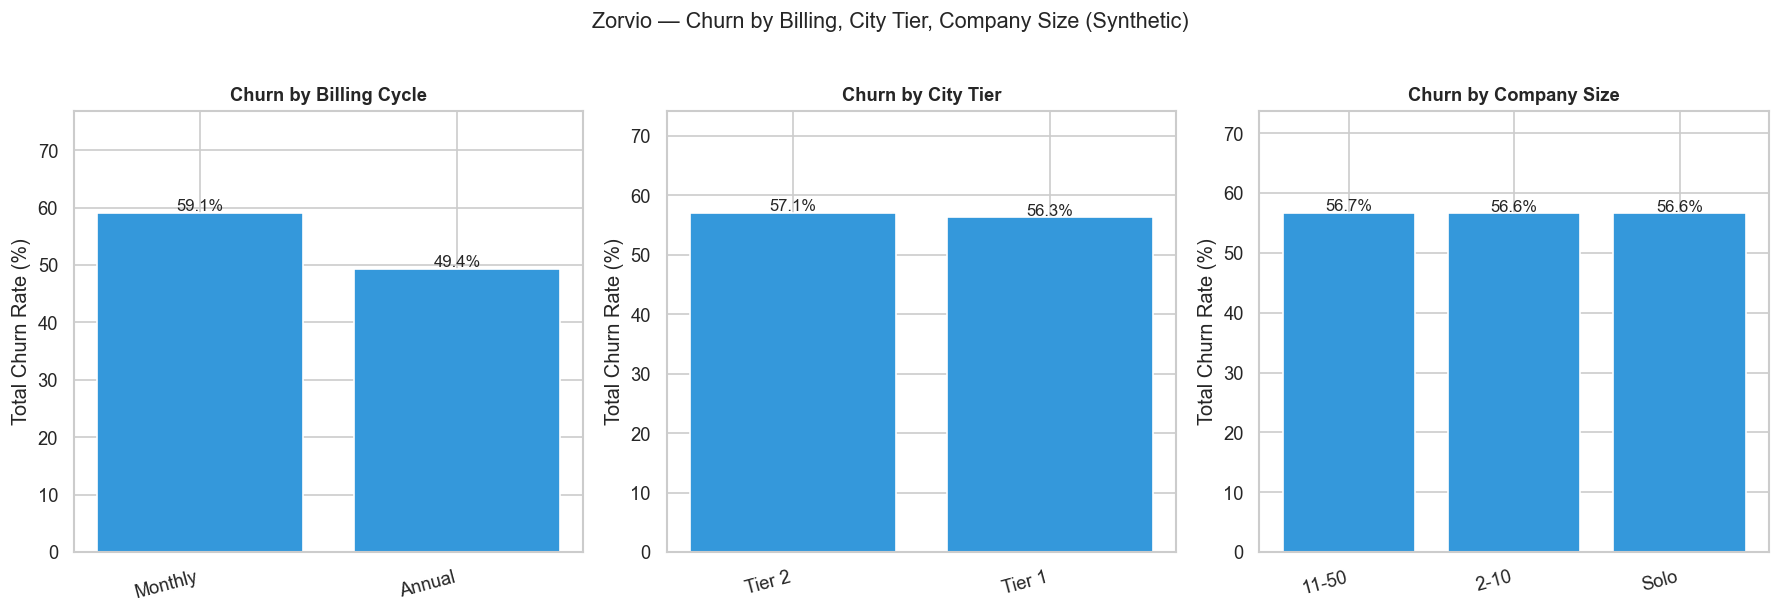

In [4]:
df_billing = pd.read_sql('SELECT * FROM churn_by_billing_cycle', conn)
df_tier    = pd.read_sql('SELECT * FROM churn_by_city_tier', conn)
df_size    = pd.read_sql('SELECT * FROM churn_by_company_size', conn)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, df, col, title in [
    (axes[0], df_billing, 'billing_cycle', 'Churn by Billing Cycle'),
    (axes[1], df_tier,    'city_tier',     'Churn by City Tier'),
    (axes[2], df_size,    'company_size_band', 'Churn by Company Size'),
]:
    bars = ax.bar(df[col], df['total_churn_pct'], color='#3498db', edgecolor='white')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel('Total Churn Rate (%)')
    ax.set_ylim(0, df['total_churn_pct'].max() * 1.3)
    for bar, val in zip(bars, df['total_churn_pct']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f'{val:.1f}%', ha='center', fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=15, ha='right')

plt.suptitle('Zorvio — Churn by Billing, City Tier, Company Size (Synthetic)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_churn_segments.png', bbox_inches='tight')
plt.show()

## 3. Churn by Acquisition Channel (Q7) with Wilson CI

In [5]:
df_ch = pd.read_sql('SELECT * FROM churn_by_channel ORDER BY total_churn_pct DESC', conn)
print(df_ch[['acquisition_channel','total_customers','total_churn_pct','wilson_lower','wilson_upper']].to_string(index=False))

acquisition_channel  total_customers  total_churn_pct  wilson_lower  wilson_upper
          App Store             4412            58.86         57.41         60.31
 Campus/Partnership             1421            56.86         54.29         59.44
        Paid Social             7335            56.35         55.21         57.48
           Referral             4444            56.19         54.73         57.65
     Organic Search            11785            56.09         55.19         56.98
            Unknown              603            55.56         51.59         59.52


<cell>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


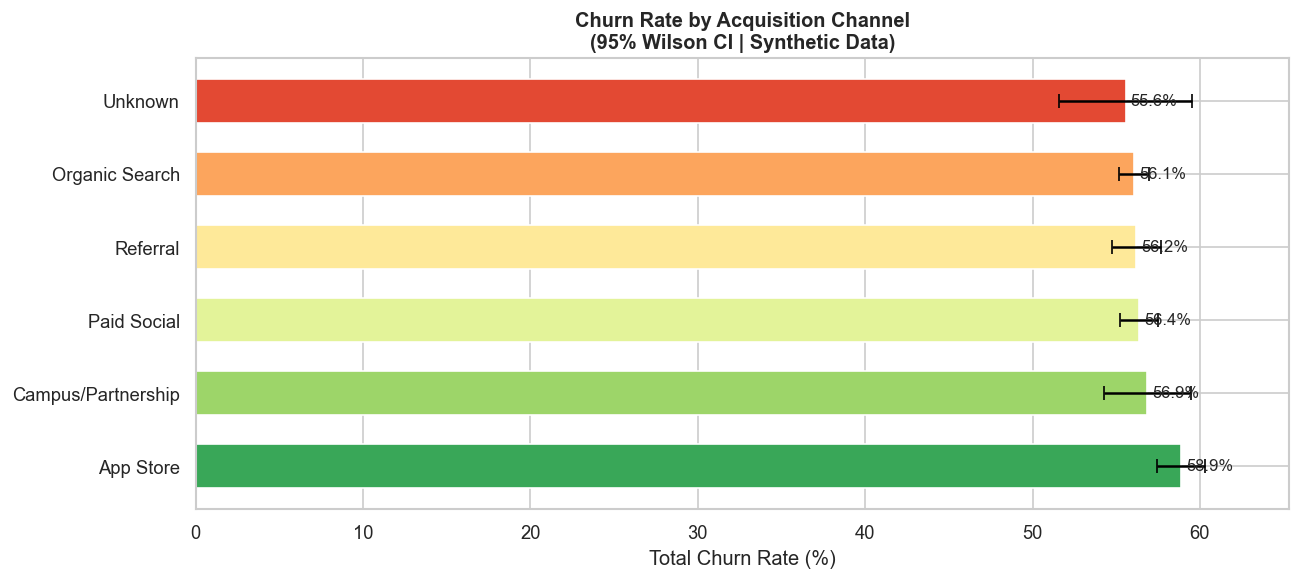

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

channels = df_ch['acquisition_channel']
mid = df_ch['total_churn_pct']
lo  = df_ch['wilson_lower']
hi  = df_ch['wilson_upper']

palette = sns.color_palette('RdYlGn_r', len(channels))
bars = ax.barh(channels, mid, color=palette, edgecolor='white', height=0.6)
ax.errorbar(mid, channels, xerr=[mid - lo, hi - mid], fmt='none', color='black', capsize=4)
for bar, val in zip(bars, mid):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=10)

ax.set_xlabel('Total Churn Rate (%)')
ax.set_title('Churn Rate by Acquisition Channel\n(95% Wilson CI | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_xlim(0, hi.max() + 5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_churn_by_channel.png', bbox_inches='tight')
plt.show()

## 4. Confounding Check: Channel × Plan

App Store is designed to push Starter plans. We check whether the channel's high churn
is driven by plan mix or is a genuine channel effect.


INTERPRETATION NOTE:
If App Store churn is high only in the Starter row, the channel effect is confounded by plan.
If App Store shows high churn across multiple plan tiers, there may be a genuine channel effect.


<cell>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


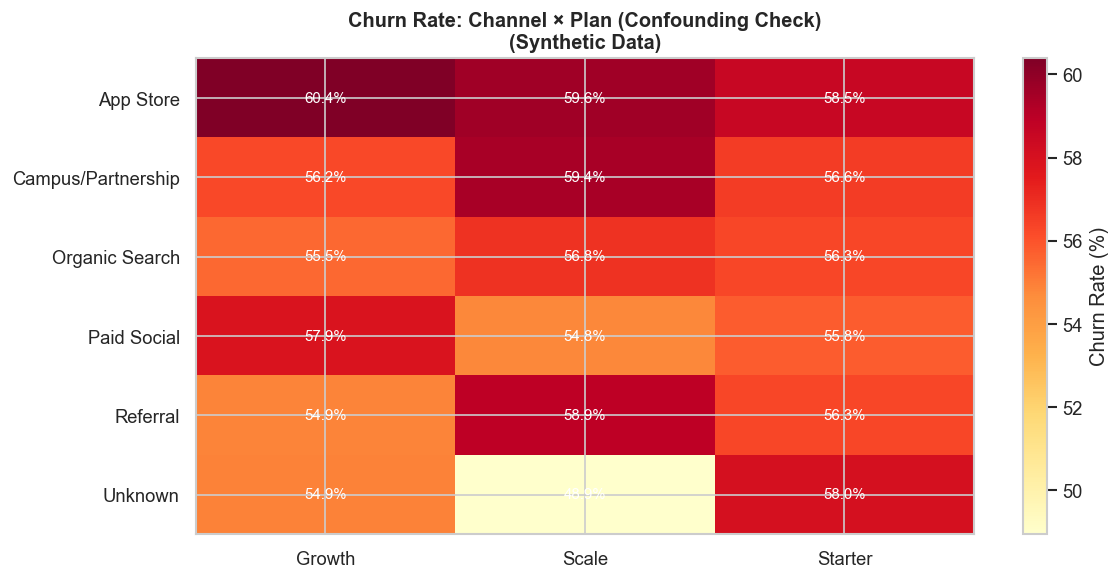

In [7]:
df_cross = pd.read_sql('SELECT * FROM churn_channel_x_plan', conn)
pivot = df_cross.pivot(index='acquisition_channel', columns='plan', values='total_churn_pct').fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(pivot.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=11)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=11)
plt.colorbar(im, ax=ax, label='Churn Rate (%)')

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        ax.text(j, i, f'{val:.1f}%', ha='center', va='center', fontsize=9,
                color='white' if val > 20 else 'black')

ax.set_title('Churn Rate: Channel × Plan (Confounding Check)\n(Synthetic Data)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_confound_channel_x_plan.png', bbox_inches='tight')
plt.show()

print()
print('INTERPRETATION NOTE:')
print('If App Store churn is high only in the Starter row, the channel effect is confounded by plan.')
print('If App Store shows high churn across multiple plan tiers, there may be a genuine channel effect.')

## 5. CAC Context (Q7 enrichment)

In [8]:
df_cac = pd.read_sql('SELECT * FROM channel_cac_context ORDER BY estimated_cac_inr', conn)
print(df_cac[['channel','customers_acquired','total_spend_inr','estimated_cac_inr']].to_string(index=False))

# Merge with churn data for ROI view
df_roi = df_cac.merge(df_ch[['acquisition_channel','total_churn_pct']], left_on='channel', right_on='acquisition_channel', how='left')
print()
print('NOTE: Lower churn AND lower CAC = best channel. Higher churn MAY be offset by lower CAC.')
print(df_roi[['channel','estimated_cac_inr','total_churn_pct']].sort_values('estimated_cac_inr').to_string(index=False))

           channel  customers_acquired  total_spend_inr  estimated_cac_inr
    Organic Search               11785       1489882.52              126.0
       Paid Social                7335       4243476.48              579.0
          Referral                4444       4460840.77             1004.0
         App Store                4412       4494718.01             1019.0
Campus/Partnership                1421       4770879.00             3357.0

NOTE: Lower churn AND lower CAC = best channel. Higher churn MAY be offset by lower CAC.
           channel  estimated_cac_inr  total_churn_pct
    Organic Search              126.0            56.09
       Paid Social              579.0            56.35
          Referral             1004.0            56.19
         App Store             1019.0            58.86
Campus/Partnership             3357.0            56.86


In [9]:
conn.close()